# 04 — Equity: do more vulnerable counties wait longer? (Objective 3)

1. **Comparable storms:** Kaplan–Meier restoration curves by SVI quartile *within* storm-intensity terciles (peak % out), plus log-rank tests per (intensity × storm type) stratum.
2. **Adjusted model:** Cox model of restoration with SVI quartile + controls (peak size, wind, customers, density, storm duration, storm type), **stratified by state** as a rough proxy for utility/regulatory differences. HR < 1 for Q4 vs Q1 means the most vulnerable counties are restored **slower**.
3. **Model fairness:** are severity and restoration predictions less accurate for high-SVI counties?

⚠️ Observational association, not causation: SVI correlates with utility territory, rurality, terrain, tree cover, and grid age.

In [1]:
# Works on Colab (Drive) or locally (repo checkout)
import os, sys, pathlib, warnings
warnings.filterwarnings("ignore")
try:
    if os.environ.get("LIGHTSOUT_PROJECT"):  # a repo checkout, e.g. run with nbconvert inside Colab
        raise ImportError
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = pathlib.Path("/content/drive/MyDrive/LightsOut")
    ZIP = pathlib.Path("/content/drive/MyDrive/LightsOut_code.zip")
    if ZIP.exists():  # refresh code (src/, notebooks/) from the latest uploaded zip; data/ is untouched
        import zipfile; zipfile.ZipFile(ZIP).extractall(PROJECT)
    !pip -q install polars lifelines scikit-survival shap geopandas lightgbm
except ImportError:
    PROJECT = pathlib.Path(os.environ["LIGHTSOUT_PROJECT"]) if os.environ.get("LIGHTSOUT_PROJECT") else \
        pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(PROJECT / "src"))
os.chdir(PROJECT)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from lightsout import config as C, viz
viz.setup()
df = pd.read_parquet(C.PROCESSED / "model_table.parquet")
print(f"{len(df):,} (storm episode, county) units, {df.fips.nunique():,} counties, years {df.year.min()}-{df.year.max()}")

226,389 (storm episode, county) units, 3,037 counties, years 2014-2022


In [2]:
from lightsout import equity as E
s = E.with_intensity(df)
print(f"{len(s):,} outage units with SVI")
pd.crosstab(s.intensity, s.svi_quartile)

70,570 outage units with SVI


svi_quartile,Q1 (least),Q2,Q3,Q4 (most)
intensity,,,,
small,4674,6016,6541,6292
medium,4826,5705,6259,6733
large,4759,5671,5922,7172


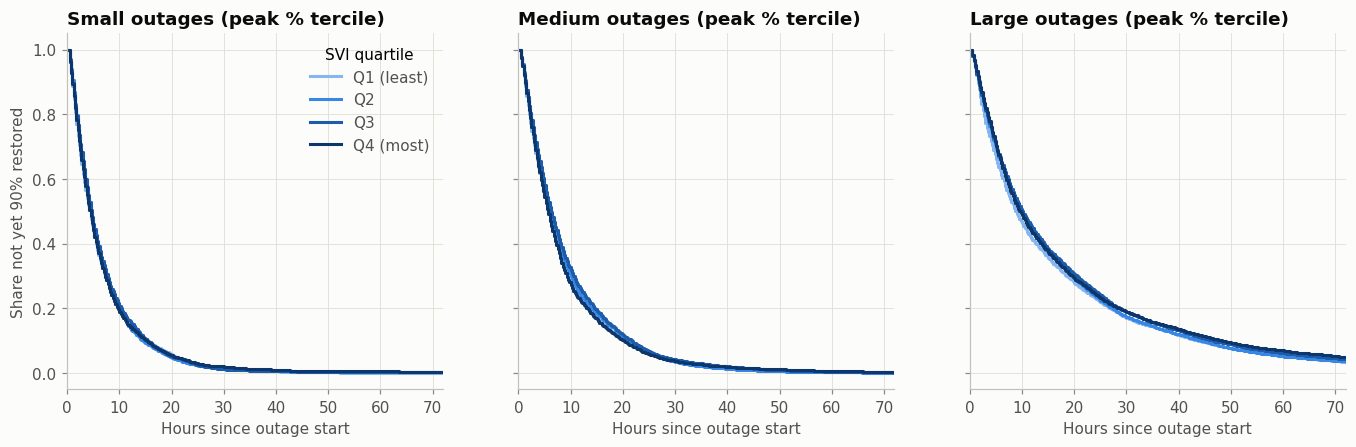

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, inten in zip(axes, ["small", "medium", "large"]):
    for (q, kmf), col in zip(E.km_by_quartile(s[s.intensity == inten]).items(), viz.SVI_COLORS):
        kmf.plot_survival_function(ax=ax, color=col, ci_show=False)
    ax.set_xlim(0, 72); ax.set_title(f"{inten.capitalize()} outages (peak % tercile)")
    ax.set_xlabel("Hours since outage start")
axes[0].set_ylabel("Share not yet 90% restored"); axes[0].legend(title="SVI quartile")
for ax in axes[1:]: ax.get_legend() and ax.get_legend().remove()
viz.save(fig, "11_km_svi_by_intensity"); fig

In [4]:
lr = E.logrank_by_stratum(s)
lr.to_csv(C.REPORTS / "equity_logrank.csv")
lr.round(4)

,intensity,storm_type,n,median_h_Q1,median_h_Q4,chi2,p_value
19,large,flood,1346,4.750,4.750,3.1053,0.3757
20,large,hail,771,2.500,4.000,4.7258,0.1930
21,large,heat,450,3.125,4.000,2.6114,0.4555
22,large,ice,523,26.500,40.875,22.0211,0.0001
23,large,tornado,1776,15.000,14.750,0.4809,0.9231
24,large,tropical,979,27.500,38.000,8.9460,0.0300
25,large,wind,13274,9.000,8.750,24.8768,0.0000
26,large,winter,4279,8.500,12.750,25.5695,0.0000
10,medium,flood,2264,3.500,4.750,13.6514,0.0034
11,medium,hail,1158,3.750,3.750,2.3090,0.5108


## Adjusted Cox model (stratified by state)

In [5]:
cq = E.cox_equity(s, "svi_quartile")
cs = E.cox_equity(s, "svi")
tab = pd.concat([cq.summary.filter(like="svi", axis=0), cs.summary.filter(like="svi", axis=0)])
tab = tab[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].round(4)
tab.to_csv(C.REPORTS / "equity_cox.csv"); (C.REPORTS / "equity_cox.md").write_text(tab.to_markdown())
tab

,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,
svi_Q2,1.0064,0.9833,1.0300,0.5885
svi_Q3,0.9560,0.9331,0.9794,0.0003
svi_Q4 (most),0.9148,0.8908,0.9395,0.0000
svi_per_10pct,0.9858,0.9824,0.9892,0.0000


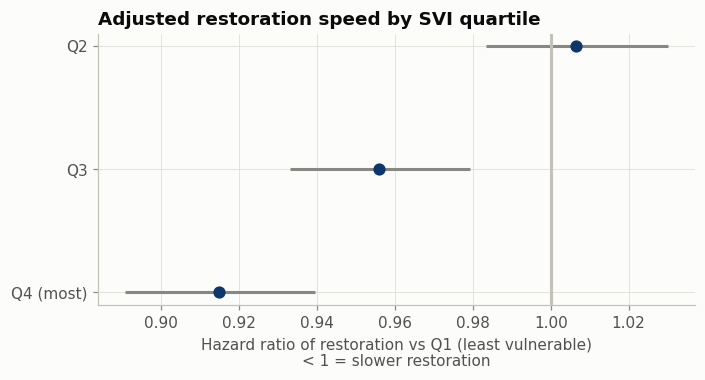

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.2))
t = cq.summary.filter(like="svi", axis=0)
y = np.arange(len(t))[::-1]
ax.errorbar(t["exp(coef)"], y, xerr=[t["exp(coef)"] - t["exp(coef) lower 95%"],
            t["exp(coef) upper 95%"] - t["exp(coef)"]], fmt="o", color=viz.SVI_COLORS[3],
            ecolor=viz.MUTED, markersize=7, capsize=0)
ax.axvline(1, color=viz.AXIS); ax.set_yticks(y, [i.replace("svi_", "") for i in t.index])
ax.set_xlabel("Hazard ratio of restoration vs Q1 (least vulnerable)\n< 1 = slower restoration")
ax.grid(axis="x"); ax.set_title("Adjusted restoration speed by SVI quartile")
viz.save(fig, "12_equity_cox_hr"); fig

In [7]:
# which SVI themes matter? one Cox model per theme (continuous, per +10 percentile points)
rows = []
for theme in ["svi", "svi_socioeconomic", "svi_household", "svi_minority", "svi_housing_transport"]:
    d = s.dropna(subset=[theme])
    r = E.cox_equity(d, theme).summary.loc["svi_per_10pct"]
    rows.append({"theme": theme, "HR per +10 pct": r["exp(coef)"],
                 "95% CI": f"{r['exp(coef) lower 95%']:.3f}-{r['exp(coef) upper 95%']:.3f}", "p": r["p"]})
pd.DataFrame(rows).round(4)

,theme,HR per +10 pct,95% CI,p
0,svi,0.9858,0.982-0.989,0.0000
1,svi_socioeconomic,0.9815,0.978-0.985,0.0000
2,svi_household,0.9955,0.992-0.999,0.0046
3,svi_minority,1.0184,1.014-1.023,0.0000
4,svi_housing_transport,0.9865,0.984-0.989,0.0000


## Do the models work equally well across SVI groups?

In [8]:
from lightsout import models_severity as S, models_survival as V
sev = S.fit_all(df); surv = V.fit_all(df)
disp = E.error_disparity(sev["truth"]["test"], sev["pred"]["test"]["LightGBM|reg"].to_numpy(),
                         surv["data"]["test"], V.risk_scores(surv, "test")["LightGBM (log hours)"])
disp.to_csv(C.REPORTS / "equity_model_error.csv")
disp

,n (severity),severity MAE (log),n (restoration),restoration C-index
SVI quartile,,,,
Q1 (least),15111,0.521,4186,0.698
Q2,15748,0.542,5186,0.702
Q3,15358,0.560,5436,0.700
Q4 (most),16886,0.581,6395,0.701


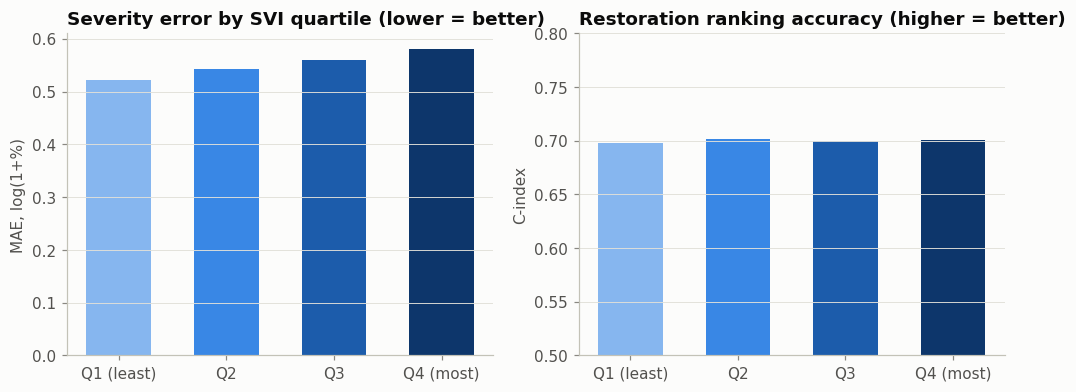

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(disp.index, disp["severity MAE (log)"], color=viz.SVI_COLORS, width=0.6)
axes[0].set_title("Severity error by SVI quartile (lower = better)"); axes[0].set_ylabel("MAE, log(1+%)")
axes[1].bar(disp.index, disp["restoration C-index"], color=viz.SVI_COLORS, width=0.6)
axes[1].set_ylim(0.5, max(0.8, disp["restoration C-index"].max() + 0.02))
axes[1].set_title("Restoration ranking accuracy (higher = better)"); axes[1].set_ylabel("C-index")
viz.save(fig, "13_model_error_by_svi"); fig